# Tugas 4 - Deteksi Titik, Garis, dan Tepi
## Bagian Nad

Nama: Nad  
Kelompok: 5

Pada notebook ini saya mengerjakan:
1. Deteksi titik pada dua citra.
2. Deteksi garis dengan mask horizontal dan vertikal.
3. Deteksi tepi Prewitt.

Citra yang digunakan adalah `image 1.jpeg` dan `image 2.jpeg`. Semua hasil disimpan di folder `output`.


## 1. Import Library

In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

folder_output = Path("output")
folder_output.mkdir(exist_ok=True)


## 2. Membaca Citra

Citra dibaca langsung dalam mode grayscale karena deteksi titik, garis, dan tepi bekerja pada nilai intensitas.


image 1 ukuran: (678, 452)
image 2 ukuran: (1200, 969)


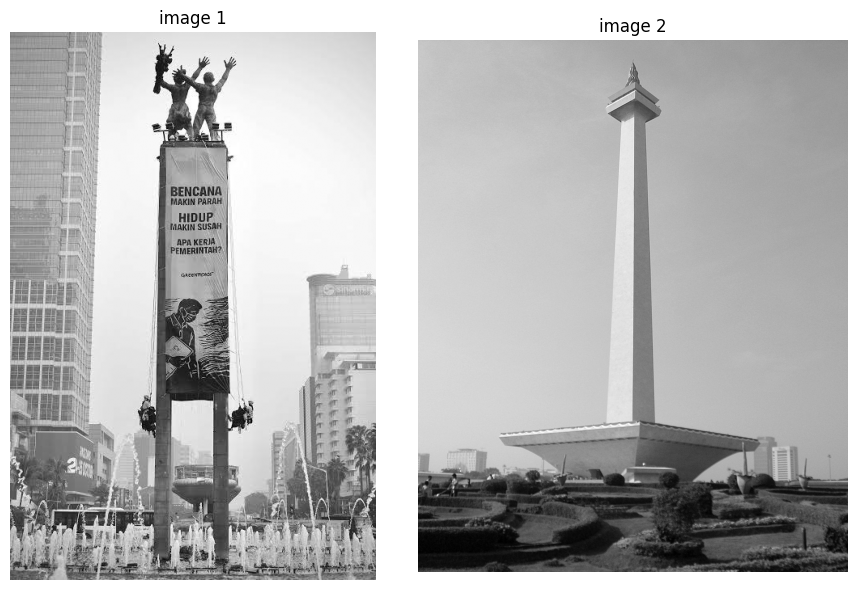

In [2]:
gambar = {}

for nama, file in [("image 1", "image 1.jpeg"), ("image 2", "image 2.jpeg")]:
    bgr = cv2.imread(file)
    gambar[nama] = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)

fig, ax = plt.subplots(1, 2, figsize=(9, 6))
for i, (nama, img) in enumerate(gambar.items()):
    print(nama, "ukuran:", img.shape)
    ax[i].imshow(img, cmap="gray")
    ax[i].set_title(nama)
    ax[i].axis("off")

plt.tight_layout()
plt.savefig(folder_output / "00_citra_input_grayscale.png", bbox_inches="tight")
plt.show()


## 3. Mask yang Digunakan

- **Titik:** pusat bernilai 8 dan delapan tetangga bernilai -1.
- **Garis horizontal:** baris tengah bernilai 2.
- **Garis vertikal:** kolom tengah bernilai 2.
- **Prewitt:** Gx untuk perubahan kiri-kanan, Gy untuk perubahan atas-bawah.

Fungsi `konvolusi` di bawah ini hanya membungkus `cv2.filter2D` agar mask bisa langsung dipakai.


In [3]:
mask_titik = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
], dtype=np.float32)

mask_horizontal = np.array([
    [-1, -1, -1],
    [ 2,  2,  2],
    [-1, -1, -1]
], dtype=np.float32)

mask_vertikal = np.array([
    [-1,  2, -1],
    [-1,  2, -1],
    [-1,  2, -1]
], dtype=np.float32)

mask_prewitt_x = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
], dtype=np.float32)

mask_prewitt_y = np.array([
    [-1, -1, -1],
    [ 0,  0,  0],
    [ 1,  1,  1]
], dtype=np.float32)


def konvolusi(img, mask):
    return cv2.filter2D(img.astype(np.float32), cv2.CV_32F, mask,
                        borderType=cv2.BORDER_REPLICATE)


data = []


## 4. Deteksi Titik

Respons titik dihitung dengan mask titik. Pixel dianggap titik jika nilai absolut responsnya melebihi threshold. Threshold diambil dari persentil 99,9 agar hasilnya tidak terlalu ramai.


image 1 | T = 931.54 | jumlah titik = 307


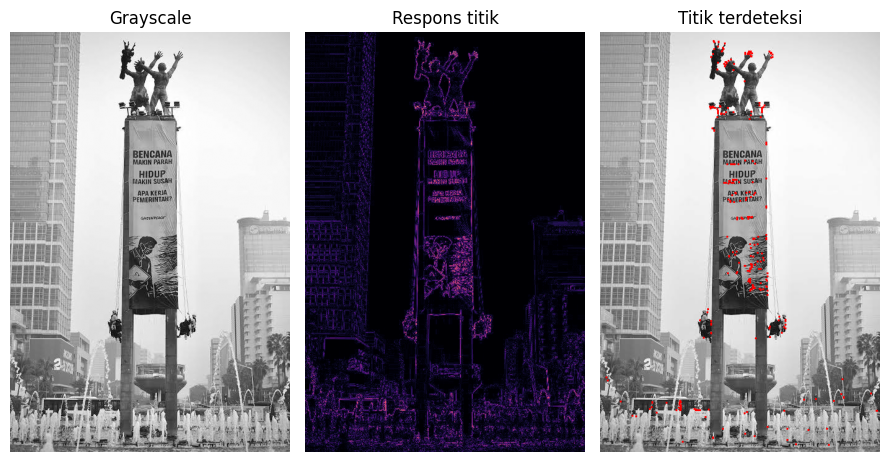

image 2 | T = 283.0 | jumlah titik = 1161


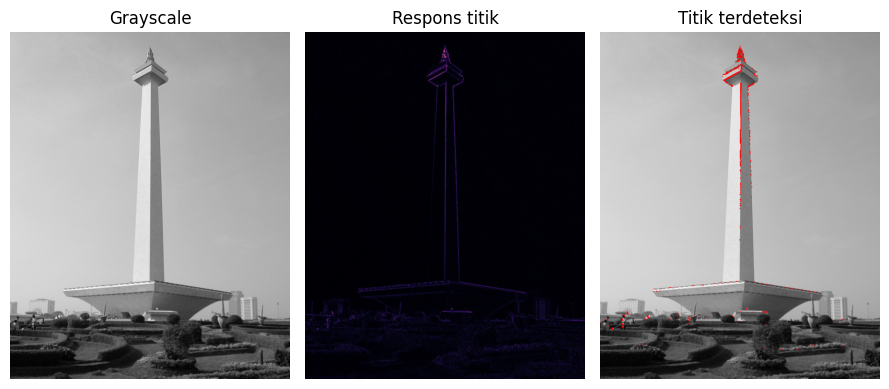

In [4]:
for nama, img in gambar.items():
    respons = konvolusi(img, mask_titik)
    nilai = np.abs(respons)

    T = np.percentile(nilai, 99.9)
    titik = nilai > T

    tampil = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    titik_tampil = cv2.dilate(titik.astype(np.uint8), np.ones((3, 3), np.uint8))
    tampil[titik_tampil == 1] = (255, 0, 0)

    print(nama, "| T =", round(T, 2), "| jumlah titik =", int(titik.sum()))

    data.append({
        "Citra": nama,
        "Metode": "Deteksi titik",
        "Mask": "[-1 -1 -1; -1 8 -1; -1 -1 -1]",
        "Threshold": round(T, 2),
        "Jumlah piksel": int(titik.sum()),
        "Persentase (%)": round(titik.sum() / img.size * 100, 3),
        "Rata-rata respons": round(float(nilai.mean()), 2),
        "Maks respons": round(float(nilai.max()), 2)
    })

    fig, ax = plt.subplots(1, 3, figsize=(9, 5))
    ax[0].imshow(img, cmap="gray")
    ax[0].set_title("Grayscale")
    ax[1].imshow(nilai, cmap="magma")
    ax[1].set_title("Respons titik")
    ax[2].imshow(tampil)
    ax[2].set_title("Titik terdeteksi")
    for a in ax:
        a.axis("off")
    plt.tight_layout()
    plt.savefig(folder_output / (nama.replace(" ", "_") + "_titik.png"), bbox_inches="tight")
    plt.show()


## 5. Deteksi Garis

Kedua mask dihitung, lalu diambil nilai absolutnya. Threshold yang dipakai sama untuk horizontal dan vertikal. Pixel yang lolos threshold diberi warna merah jika respons horizontal lebih besar, dan biru jika respons vertikal lebih besar.


image 1 | T = 574.0 | horizontal = 526 | vertikal = 999


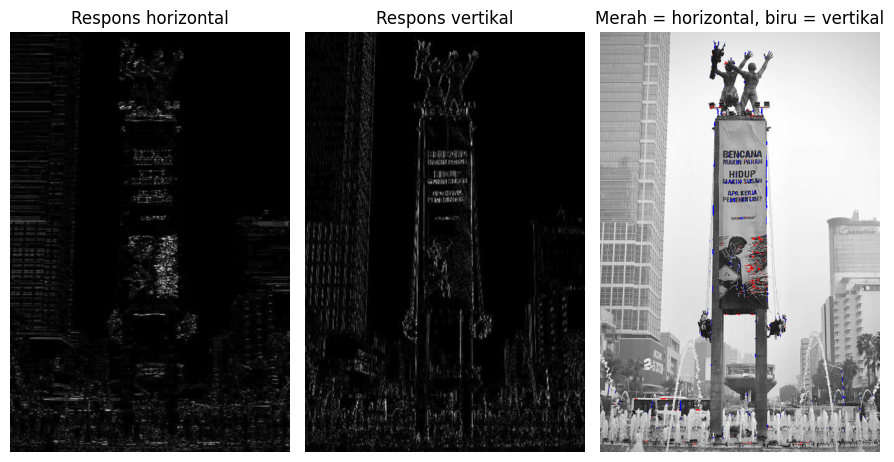

image 2 | T = 135.0 | horizontal = 2262 | vertikal = 3489


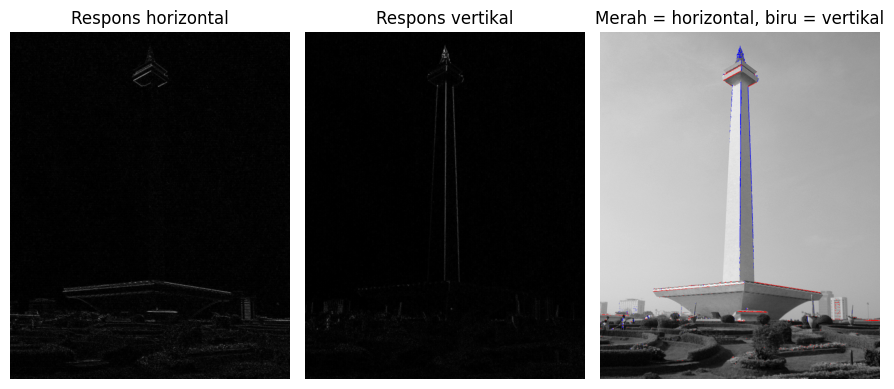

In [5]:
for nama, img in gambar.items():
    rh = konvolusi(img, mask_horizontal)
    rv = konvolusi(img, mask_vertikal)

    ah = np.abs(rh)
    av = np.abs(rv)

    T = np.percentile(np.maximum(ah, av), 99.5)

    garis_h = (ah > T) & (ah >= av)
    garis_v = (av > T) & (av > ah)

    tampil = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    tampil[garis_h] = (255, 0, 0)
    tampil[garis_v] = (0, 0, 255)

    print(nama, "| T =", round(T, 2),
          "| horizontal =", int(garis_h.sum()),
          "| vertikal =", int(garis_v.sum()))

    data.append({
        "Citra": nama,
        "Metode": "Garis horizontal",
        "Mask": "[-1 -1 -1; 2 2 2; -1 -1 -1]",
        "Threshold": round(T, 2),
        "Jumlah piksel": int(garis_h.sum()),
        "Persentase (%)": round(garis_h.sum() / img.size * 100, 3),
        "Rata-rata respons": round(float(ah.mean()), 2),
        "Maks respons": round(float(ah.max()), 2)
    })

    data.append({
        "Citra": nama,
        "Metode": "Garis vertikal",
        "Mask": "[-1 2 -1; -1 2 -1; -1 2 -1]",
        "Threshold": round(T, 2),
        "Jumlah piksel": int(garis_v.sum()),
        "Persentase (%)": round(garis_v.sum() / img.size * 100, 3),
        "Rata-rata respons": round(float(av.mean()), 2),
        "Maks respons": round(float(av.max()), 2)
    })

    fig, ax = plt.subplots(1, 3, figsize=(9, 5))
    ax[0].imshow(ah, cmap="gray")
    ax[0].set_title("Respons horizontal")
    ax[1].imshow(av, cmap="gray")
    ax[1].set_title("Respons vertikal")
    ax[2].imshow(tampil)
    ax[2].set_title("Merah = horizontal, biru = vertikal")
    for a in ax:
        a.axis("off")
    plt.tight_layout()
    plt.savefig(folder_output / (nama.replace(" ", "_") + "_garis.png"), bbox_inches="tight")
    plt.show()


## 6. Deteksi Tepi Prewitt

Gx dan Gy dihitung terpisah. Besar gradien dihitung dengan `|Gx| + |Gy|`, lalu di-threshold pada persentil 99,0.


image 1 | T = 514.45 | jumlah tepi = 3065


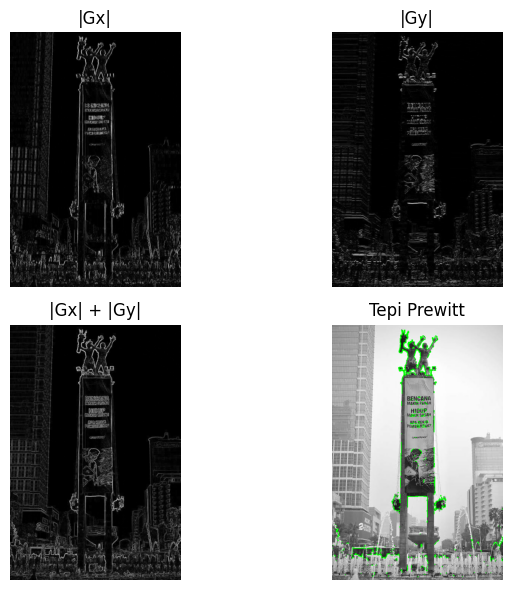

image 2 | T = 184.0 | jumlah tepi = 11620


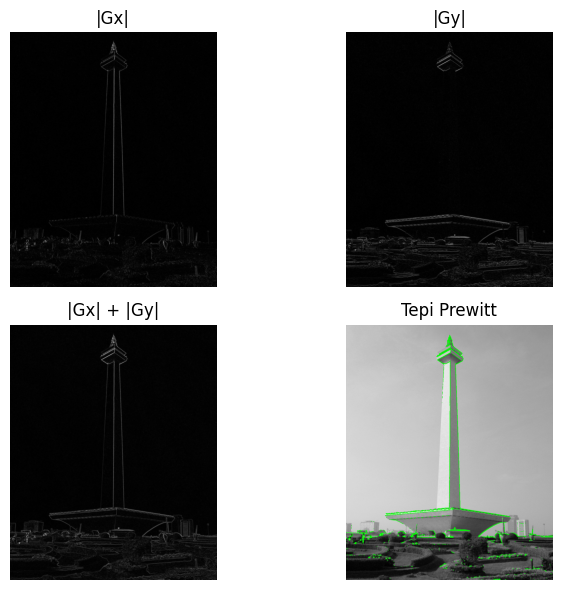

In [6]:
for nama, img in gambar.items():
    gx = konvolusi(img, mask_prewitt_x)
    gy = konvolusi(img, mask_prewitt_y)

    magnitudo = np.abs(gx) + np.abs(gy)
    T = np.percentile(magnitudo, 99.0)
    tepi = magnitudo > T

    tampil = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    tepi_tampil = cv2.dilate(tepi.astype(np.uint8), np.ones((2, 2), np.uint8))
    tampil[tepi_tampil == 1] = (0, 255, 0)

    print(nama, "| T =", round(T, 2), "| jumlah tepi =", int(tepi.sum()))

    data.append({
        "Citra": nama,
        "Metode": "Prewitt",
        "Mask": "Gx dan Gy",
        "Threshold": round(T, 2),
        "Jumlah piksel": int(tepi.sum()),
        "Persentase (%)": round(tepi.sum() / img.size * 100, 3),
        "Rata-rata respons": round(float(magnitudo.mean()), 2),
        "Maks respons": round(float(magnitudo.max()), 2)
    })

    fig, ax = plt.subplots(2, 2, figsize=(8, 6))
    ax[0, 0].imshow(np.abs(gx), cmap="gray")
    ax[0, 0].set_title("|Gx|")
    ax[0, 1].imshow(np.abs(gy), cmap="gray")
    ax[0, 1].set_title("|Gy|")
    ax[1, 0].imshow(magnitudo, cmap="gray")
    ax[1, 0].set_title("|Gx| + |Gy|")
    ax[1, 1].imshow(tampil)
    ax[1, 1].set_title("Tepi Prewitt")
    for a in ax.ravel():
        a.axis("off")
    plt.tight_layout()
    plt.savefig(folder_output / (nama.replace(" ", "_") + "_prewitt.png"), bbox_inches="tight")
    plt.show()


## 7. Tabel Hasil

In [7]:
tabel = pd.DataFrame(data)
tabel


,Citra,Metode,Mask,Threshold,Jumlah piksel,Persentase (%),Rata-rata respons,Maks respons
0,image 1,Deteksi titik,[-1 -1 -1; -1 8 -1; -1 -1 -1],931.539978,307,0.100,74.35,1575.0
1,image 2,Deteksi titik,[-1 -1 -1; -1 8 -1; -1 -1 -1],283.000000,1161,0.100,16.17,924.0
2,image 1,Garis horizontal,[-1 -1 -1; 2 2 2; -1 -1 -1],574.000000,526,0.172,34.48,1125.0
3,image 1,Garis vertikal,[-1 2 -1; -1 2 -1; -1 2 -1],574.000000,999,0.326,46.42,1246.0
4,image 2,Garis horizontal,[-1 -1 -1; 2 2 2; -1 -1 -1],135.000000,2262,0.195,9.33,447.0
5,image 2,Garis vertikal,[-1 2 -1; -1 2 -1; -1 2 -1],135.000000,3489,0.300,8.25,744.0
6,image 1,Prewitt,Gx dan Gy,514.450012,3065,1.000,71.48,963.0
7,image 2,Prewitt,Gx dan Gy,184.000000,11620,0.999,21.35,749.0


In [8]:
tabel.to_csv(folder_output / "statistik_nad.csv", index=False)
print("Tabel disimpan di", folder_output / "statistik_nad.csv")


Tabel disimpan di output\statistik_nad.csv


## 8. Hasil dan Analisis

| Metode | Image 1 | Image 2 |
|---|---:|---:|
| Deteksi titik | 307 piksel | 1.161 piksel |
| Garis horizontal | 526 piksel | 2.262 piksel |
| Garis vertikal | 999 piksel | 3.489 piksel |
| Prewitt | 3.065 piksel | 11.620 piksel |

**Deteksi titik.** Mask titik memberi respons besar saat pixel pusat berbeda dari delapan tetangganya. Pada image 1, titik banyak muncul di teks banner, patung, gedung, dan air mancur. Pada image 2, titik mengikuti sisi tugu, dasar Monas, dan batas vegetasi. Mask ini cukup sensitif terhadap tekstur dan sudut objek.

**Deteksi garis.** Garis vertikal lebih banyak daripada garis horizontal pada kedua citra. Pada image 1, garis vertikal mengikuti gedung dan tiang. Pada image 2, garis vertikal mengikuti badan Monas. Garis horizontal terlihat pada teks banner, dasar tugu, dan batas vegetasi. Hasil garis masih terputus-putus karena mask hanya mendeteksi segmen pendek dengan arah tertentu.

**Prewitt.** Prewitt menghasilkan tepi yang paling jelas dan menyatu. Batas objek seperti banner, patung, gedung, Monas, dan dasar tugu terlihat sebagai rangkaian tepi. Kekurangannya, Prewitt masih ikut mendeteksi tekstur seperti air mancur dan vegetasi.

**Kesimpulan.** Dari tiga metode bagian Nad, Prewitt memberikan hasil tepi paling jelas. Deteksi garis berguna untuk melihat arah dominan, sedangkan deteksi titik paling mudah terganggu oleh tekstur.
